# Atividade Prática 1 : AutoML para previsão da Produção de Arroz

## Nome : Victor Hugo Oliveira da Silva Nusp 11320901
## Professor: Dr. Fabio Manoel França Lobato
## Disciplina: Aplicações de Aprendizado de Máquina e Mineração de Dados (SCC 0233)

In [1]:
!git --version
!mkdir -p data && cd data && git clone https://github.com/rgrion/mlarrozprevisao.git
DATASET_PATH="data/mlarrozprevisao/Datasets_NASA_FAOSTAT/dataset_NASA_FAOSTAT.csv"


git version 2.34.1
Cloning into 'mlarrozprevisao'...
remote: Enumerating objects: 236, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (32/32), done.
remote: Total 236 (delta 27), reused 8 (delta 8), pack-reused 196 (from 1)
Receiving objects: 100% (236/236), 2.28 MiB | 7.97 MiB/s, done.
Resolving deltas: 100% (107/107), done.


In [2]:
!pip install flaml[automl] -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 349.7/349.7 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 342.1/342.1 MB 1.6 MB/s eta 0:00:00


## 1. Análise Exploratória de Dados

Vamos validar a integridade e ver caracteristicas do dataset.

### Range de anos

O dataset contempla os dados entre os ano de 2011 e 2023

### Numero de países

Temos os 12 países da America do Sul

### Valores Null

As linhas estão sem valores faltantes.

In [3]:
from os import listdir, path
from sys import exit

if path.exists(DATASET_PATH) != True:
    exit(1)


import pandas as pd
import numpy as np

df = pd.read_csv(DATASET_PATH)
df = df.rename(columns={'Pais': 'Area'})

print(df.shape)
print("-------------------------------------")
print(df['Year'].min(), df['Year'].max())
print("-------------------------------------")
print(df['Area'].nunique(), "países")
print("-------------------------------------")
print(df.isna().sum())
print("-------------------------------------")
df.groupby('Area')['Year'].count().sort_values()

(156, 7)
-------------------------------------
2011 2023
-------------------------------------
12 países
-------------------------------------
Area                   0
Year                   0
Production (t)         0
Area harvested (ha)    0
Yield (kg/ha)          0
Temp_Media_C           0
Precipitacao_mm        0
dtype: int64
-------------------------------------


,Year
Area,
Argentina,13
Bolivia (Plurinational State of),13
Brazil,13
Chile,13
Colombia,13
Ecuador,13
Guyana,13
Paraguay,13
Peru,13


### 1.1 Verificação de relação funcional entre atributos

O artigo de referência afirma, na Seção 3.1, que a produção é função direta da
área colhida e da produtividade. Esta célula quantifica essa relação.

In [4]:
prod_calc = df['Area harvested (ha)'] * df['Yield (kg/ha)'] / 1000
erro_rel = ((prod_calc - df['Production (t)']).abs() / df['Production (t)']) * 100

print(f"Erro relativo médio:  {erro_rel.mean():.4f} %")
print(f"Erro relativo máximo: {erro_rel.max():.4f} %")
print(f"Correlação: {np.corrcoef(prod_calc, df['Production (t)'])[0,1]:.6f}")

Erro relativo médio:  0.0005 %
Erro relativo máximo: 0.0020 %
Correlação: 1.000000


O teste confirma que `Production (t)` é obtida exatamente pelo produto entre
`Area harvested (ha)` e `Yield (kg/ha)`: erro relativo médio de 0,0005%, erro
máximo de 0,0020% e correlação igual a 1,000000 nas 156 observações.

Aqui temos um "target leakage", quando uma feature usada no treino carrega informação sobre a resposta que não estaria disponível no momento real da previsão. O modelo "cola" — vai muito bem na validação e desaba em produção.

In [5]:
FEATURES_A = ['Year', 'Area harvested (ha)', 'Yield (kg/ha)',
              'Temp_Media_C', 'Precipitacao_mm']

df = df.sort_values(['Area', 'Year']).reset_index(drop=True)
g = df.groupby('Area')

for col in ['Production (t)', 'Area harvested (ha)', 'Yield (kg/ha)',
            'Temp_Media_C', 'Precipitacao_mm']:
    df[f'{col}_lag1'] = g[col].shift(1)

FEATURES_B = ['Area', 'Year'] + [c for c in df.columns if c.endswith(('_lag1'))]

df.head()


,Area,Year,Production (t),Area harvested (ha),Yield (kg/ha),Temp_Media_C,Precipitacao_mm,Production (t)_lag1,Area harvested (ha)_lag1,Yield (kg/ha)_lag1,Temp_Media_C_lag1,Precipitacao_mm_lag1
0,Argentina,2011,1748075.0,257445.0,6790.1,16.85,22.72,NaN,NaN,NaN,NaN,NaN
1,Argentina,2012,1567971.0,235372.0,6661.7,16.53,42.07,1748075.0,257445.0,6790.1,16.85,22.72
2,Argentina,2013,1563450.0,232700.0,6718.7,17.00,22.20,1567971.0,235372.0,6661.7,16.53,42.07
3,Argentina,2014,1581810.0,243200.0,6504.2,16.79,38.19,1563450.0,232700.0,6718.7,17.00,22.20
4,Argentina,2015,1558100.0,232590.0,6698.9,16.63,35.19,1581810.0,243200.0,6504.2,16.79,38.19


### Construção dos atributos do artigo e cenario com defasados

Vamos construir dois cenários, onde o cenário A será igual ao do artigo e o cenário B com defasagem, foram construídas defasagens de 1 ano (*lag*) de todos os atributos, de modo que a previsão de um ano utilize exclusivamente informação
observada até o ano anterior.

In [6]:
def split(df, features, target='Production (t)'):
    d = df.dropna(subset=features + [target])
    tr = d[d['Year'] <= 2020]
    te = d[d['Year'] >= 2021]
    return tr[features + [target]], te[features + [target]]

train_A, test_A = split(df, FEATURES_A)
train_B, test_B = split(df, FEATURES_B)

print(train_A.shape, test_A.shape)
print(train_B.shape, test_B.shape)

(120, 6) (36, 6)
(108, 8) (36, 8)


In [7]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error
import numpy as np, pandas as pd, time

TARGET = 'Production (t)'

# Registro central de resultados: (cenario, estrategia, metodo) -> metricas
RESULTADOS = {}
DETALHES   = []   # erro por observacao, para os graficos por pais/ano


def _registra(cenario, estrategia, metodo, idx, y_true, y_pred, dur, modelo=''):
    """Guarda metricas agregadas e o erro de cada observacao."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    RESULTADOS[(cenario, estrategia, metodo)] = {
        'MAPE': mean_absolute_percentage_error(y_true, y_pred) * 100,
        'MAE':  mean_absolute_error(y_true, y_pred),
        'RMSE': float(np.sqrt(((y_true - y_pred) ** 2).mean())),
        'tempo_s': dur,
        'modelo': modelo,
    }
    for i, yt, yp in zip(idx, y_true, y_pred):
        DETALHES.append({
            'Cenario': cenario, 'Estrategia': estrategia, 'Metodo': metodo,
            'Area': df.loc[i, 'Area'], 'Ano': int(df.loc[i, 'Year']),
            'Erro_pct': abs(yp - yt) / yt * 100,
        })


def _mostra(cenario, estrategia, metodo):
    r = RESULTADOS[(cenario, estrategia, metodo)]
    print(f"[{cenario} | {estrategia} | {metodo}] {r['modelo']}")
    print(f"  MAPE: {r['MAPE']:.2f} %   MAE: {r['MAE']:,.0f} t   "
          f"RMSE: {r['RMSE']:,.0f} t   tempo: {r['tempo_s']:.2f} s\n")


XGB_ARTIGO = dict(objective='reg:squarederror', n_estimators=200, max_depth=4,
                  learning_rate=0.08, subsample=0.9, colsample_bytree=0.9,
                  random_state=42)


def avalia(train, test, features, cenario):
    """XGBoost com hiperparametros do artigo, modelo global."""
    t0 = time.time()
    m = XGBRegressor(enable_categorical=True, **XGB_ARTIGO).fit(
        train[features], train[TARGET])
    dur = time.time() - t0
    pred = m.predict(test[features])
    _registra(cenario, 'global', 'manual', test.index, test[TARGET], pred,
              dur, 'XGBoost (artigo)')
    _mostra(cenario, 'global', 'manual')
    return m, pred


def avalia_por_pais(df, features, cenario):
    """XGBoost com hiperparametros do artigo, um modelo por pais."""
    tr_all = df[df['Year'] <= 2020]
    ts_all = df[df['Year'] >= 2021]
    idx, reais, preds = [], [], []

    t0 = time.time()
    for p in sorted(df['Area'].unique()):
        tr = tr_all[tr_all['Area'] == p].dropna(subset=features + [TARGET])
        ts = ts_all[ts_all['Area'] == p].dropna(subset=features + [TARGET])
        if len(tr) < 2 or ts.empty:
            continue
        m = XGBRegressor(**XGB_ARTIGO).fit(tr[features], tr[TARGET])
        idx.extend(ts.index); reais.extend(ts[TARGET])
        preds.extend(m.predict(ts[features]))
    dur = time.time() - t0

    _registra(cenario, 'por pais', 'manual', idx, reais, preds,
              dur, 'XGBoost (artigo)')
    _mostra(cenario, 'por pais', 'manual')
    return np.array(reais), np.array(preds)


# --- Execucao: 4 configuracoes com hiperparametros do artigo -----------------
# Cenario A (atributos do ano-alvo)
_ = avalia(train_A, test_A, FEATURES_A, 'A')
_ = avalia_por_pais(df, FEATURES_A, 'A')

# Cenario B (atributos defasados). 'Area' e categorica no modelo global
# e removida no modelo por pais, onde seria constante.
for d in (train_B, test_B):
    d['Area'] = d['Area'].astype('category')

FEATURES_B_pais = [c for c in FEATURES_B if c != 'Area']

_ = avalia(train_B, test_B, FEATURES_B, 'B')
_ = avalia_por_pais(df, FEATURES_B_pais, 'B')

[A | global | manual] XGBoost (artigo)
  MAPE: 31.29 %   MAE: 562,909 t   RMSE: 1,573,658 t   tempo: 0.17 s

[A | por pais | manual] XGBoost (artigo)
  MAPE: 9.14 %   MAE: 113,813 t   RMSE: 196,286 t   tempo: 0.68 s

[B | global | manual] XGBoost (artigo)
  MAPE: 14.11 %   MAE: 137,821 t   RMSE: 241,990 t   tempo: 0.32 s

[B | por pais | manual] XGBoost (artigo)
  MAPE: 13.79 %   MAE: 137,020 t   RMSE: 215,400 t   tempo: 0.62 s



In [8]:
from flaml import AutoML
import time

def roda_automl(train, test, features, cenario, budget=90):
    """Busca automatizada, modelo global."""
    aml = AutoML()
    t0 = time.time()
    aml.fit(X_train=train[features], y_train=train[TARGET], task="regression",
            metric="mape", time_budget=budget, verbose=1, seed=42)
    dur = time.time() - t0

    pred = aml.predict(test[features])
    _registra(cenario, 'global', 'automl', test.index, test[TARGET], pred,
              dur, aml.best_estimator)
    print(f"Hiperparametros: {aml.best_config}")
    _mostra(cenario, 'global', 'automl')
    return aml, pred


def automl_por_pais(df, features, cenario, budget_pais=15):
    """Busca automatizada, um modelo por pais."""
    tr_all = df[df['Year'] <= 2020]
    ts_all = df[df['Year'] >= 2021]
    idx, reais, preds, escolhas = [], [], [], []

    t0 = time.time()
    for p in sorted(df['Area'].unique()):
        tr = tr_all[tr_all['Area'] == p].dropna(subset=features + [TARGET])
        ts = ts_all[ts_all['Area'] == p].dropna(subset=features + [TARGET])
        if len(tr) < 4 or ts.empty:
            continue

        aml = AutoML()
        aml.fit(X_train=tr[features], y_train=tr[TARGET], task="regression",
                metric="mape", time_budget=budget_pais, eval_method="cv",
                n_splits=3, verbose=0, seed=42)

        idx.extend(ts.index); reais.extend(ts[TARGET])
        preds.extend(aml.predict(ts[features]))
        escolhas.append({'Pais': p, 'Modelo': aml.best_estimator,
                         'Config': aml.best_config})
    dur = time.time() - t0

    esc = pd.DataFrame(escolhas)
    freq = esc['Modelo'].value_counts().to_dict()
    _registra(cenario, 'por pais', 'automl', idx, reais, preds, dur, str(freq))
    _mostra(cenario, 'por pais', 'automl')
    return esc, np.array(reais), np.array(preds)

In [9]:
# AutoML, modelo global (orcamento de 90 s por cenario)
aml_A_glob, pred_A_glob = roda_automl(train_A, test_A, FEATURES_A, 'A', budget=90)

# No modelo global do Cenario B, o pais entra codificado numericamente
for d in (train_B, test_B):
    d['Area'] = d['Area'].astype('category').cat.codes

aml_B_glob, pred_B_glob = roda_automl(train_B, test_B, FEATURES_B, 'B', budget=90)

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune
INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


Hiperparametros: {'n_estimators': 4, 'max_features': np.float64(0.9021725258450654), 'max_leaves': 59}
[A | global | automl] extra_tree
  MAPE: 11.50 %   MAE: 132,856 t   RMSE: 229,653 t   tempo: 89.96 s

Hiperparametros: {'n_estimators': 6, 'max_features': np.float64(0.6143487157107971), 'max_leaves': 33}
[B | global | automl] extra_tree
  MAPE: 14.88 %   MAE: 139,342 t   RMSE: 206,490 t   tempo: 90.02 s



In [10]:
# AutoML por pais, Cenario A (orcamento de 15 s por pais)
esc_A, real_A_pais, pred_A_pais = automl_por_pais(df, FEATURES_A, 'A',
                                                  budget_pais=15)

print("Modelos selecionados por pais (Cenario A):")
print(esc_A[['Pais', 'Modelo']].to_string(index=False))

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/sea

[A | por pais | automl] {'extra_tree': 8, 'rf': 3, 'xgboost': 1}
  MAPE: 8.29 %   MAE: 90,576 t   RMSE: 136,776 t   tempo: 180.69 s

Modelos selecionados por pais (Cenario A):
                              Pais     Modelo
                         Argentina         rf
  Bolivia (Plurinational State of) extra_tree
                            Brazil         rf
                             Chile extra_tree
                          Colombia         rf
                           Ecuador extra_tree
                            Guyana extra_tree
                          Paraguay extra_tree
                              Peru extra_tree
                          Suriname extra_tree
                           Uruguay    xgboost
Venezuela (Bolivarian Republic of) extra_tree


In [11]:
# AutoML por pais, Cenario B (orcamento de 15 s por pais)
esc_B, real_B_pais, pred_B_pais = automl_por_pais(df, FEATURES_B_pais, 'B',
                                                  budget_pais=15)

print("Modelos selecionados por pais (Cenario B):")
print(esc_B[['Pais', 'Modelo']].to_string(index=False))

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/sea

[B | por pais | automl] {'xgboost': 7, 'xgb_limitdepth': 2, 'extra_tree': 2, 'rf': 1}
  MAPE: 19.86 %   MAE: 200,869 t   RMSE: 274,501 t   tempo: 180.78 s

Modelos selecionados por pais (Cenario B):
                              Pais         Modelo
                         Argentina xgb_limitdepth
  Bolivia (Plurinational State of)             rf
                            Brazil        xgboost
                             Chile        xgboost
                          Colombia xgb_limitdepth
                           Ecuador     extra_tree
                            Guyana        xgboost
                          Paraguay     extra_tree
                              Peru        xgboost
                          Suriname        xgboost
                           Uruguay        xgboost
Venezuela (Bolivarian Republic of)        xgboost


## 6. Consolidacao dos resultados

Todas as metricas foram registradas no dicionario `RESULTADOS` durante a
execucao das celulas anteriores. A tabela abaixo e construida diretamente a
partir dele, sem valores digitados manualmente.

In [12]:
# Tabela consolidada, montada a partir do registro de resultados
tabela = (pd.DataFrame(RESULTADOS).T
            .rename_axis(['Cenario', 'Estrategia', 'Metodo'])
            .reset_index())

pivot = tabela.pivot_table(index=['Cenario', 'Estrategia'],
                           columns='Metodo', values='MAPE').round(2)
pivot.columns = ['AutoML (MAPE %)', 'Manual (MAPE %)']
pivot = pivot[['Manual (MAPE %)', 'AutoML (MAPE %)']]

print(pivot.to_string())
print()
print(tabela[['Cenario', 'Estrategia', 'Metodo', 'modelo',
              'MAPE', 'MAE', 'tempo_s']].round(2).to_string(index=False))

                   Manual (MAPE %) AutoML (MAPE %)
Cenario Estrategia                                
A       global           31.291321       11.497976
        por pais          9.140398        8.290525
B       global           14.107976       14.876739
        por pais         13.793103        19.85804

Cenario Estrategia Metodo                                                        modelo       MAPE            MAE     tempo_s
      A     global manual                                              XGBoost (artigo)  31.291321  562909.196528    0.171657
      A   por pais manual                                              XGBoost (artigo)   9.140398  113812.636788    0.679593
      B     global manual                                              XGBoost (artigo)  14.107976  137820.929878    0.315024
      B   por pais manual                                              XGBoost (artigo)  13.793103  137019.861302    0.624793
      A     global automl                                      

## 7. Visualizacao dos resultados

### 7.1 Comparativo geral de MAPE

Formato analogo as Figuras 5 e 13 do artigo de referencia, contrastando a
configuracao manual dos autores com a solucao selecionada por AutoML.

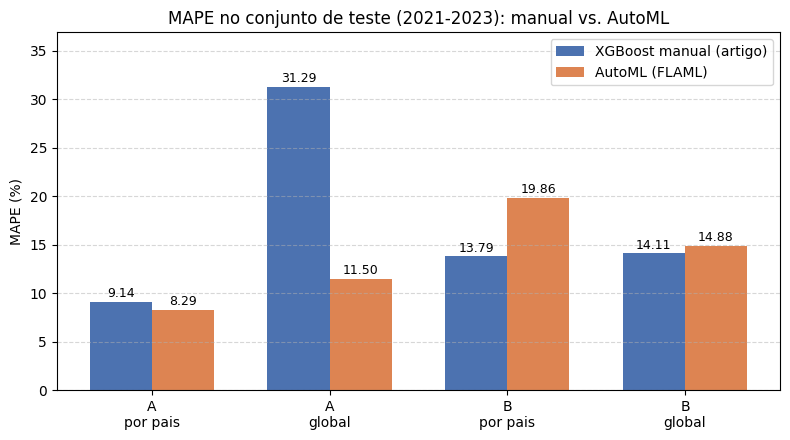

In [13]:
import matplotlib.pyplot as plt

ordem = [('A', 'por pais'), ('A', 'global'),
         ('B', 'por pais'), ('B', 'global')]
rotulos = [f"{c}\n{e}" for c, e in ordem]

manual = [RESULTADOS[(c, e, 'manual')]['MAPE'] for c, e in ordem]
automl = [RESULTADOS[(c, e, 'automl')]['MAPE'] for c, e in ordem]

x = np.arange(len(ordem)); w = 0.35
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w/2, manual, w, label='XGBoost manual (artigo)', color='#4C72B0')
ax.bar(x + w/2, automl, w, label='AutoML (FLAML)', color='#DD8452')

for i, (m, a) in enumerate(zip(manual, automl)):
    ax.text(i - w/2, m + 0.5, f'{m:.2f}', ha='center', fontsize=9)
    ax.text(i + w/2, a + 0.5, f'{a:.2f}', ha='center', fontsize=9)

ax.set_xticks(x); ax.set_xticklabels(rotulos)
ax.set_ylabel('MAPE (%)')
ax.set_title('MAPE no conjunto de teste (2021-2023): manual vs. AutoML')
ax.legend(); ax.grid(axis='y', ls='--', alpha=.5)
ax.set_ylim(0, max(manual + automl) * 1.18)
plt.tight_layout()
plt.savefig('fig_comparativo.png', dpi=150)
plt.show()

### 7.2 Erro percentual medio por pais

Formato analogo as Figuras 7, 9 e 12 do artigo. Permite identificar em quais
paises cada abordagem apresenta maior dificuldade.

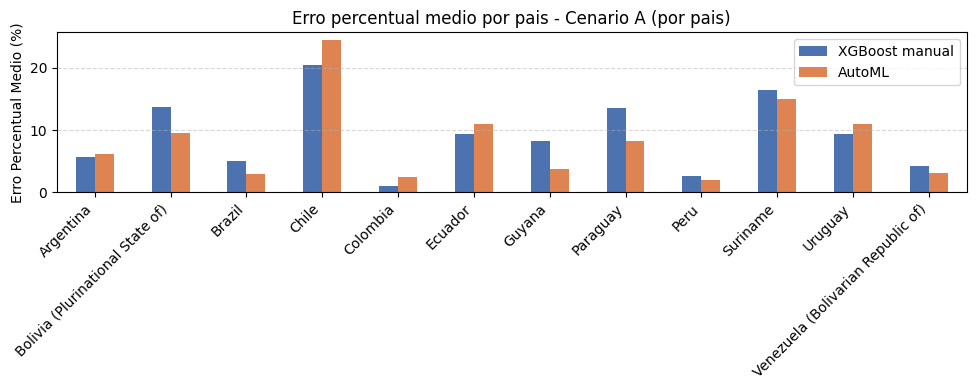

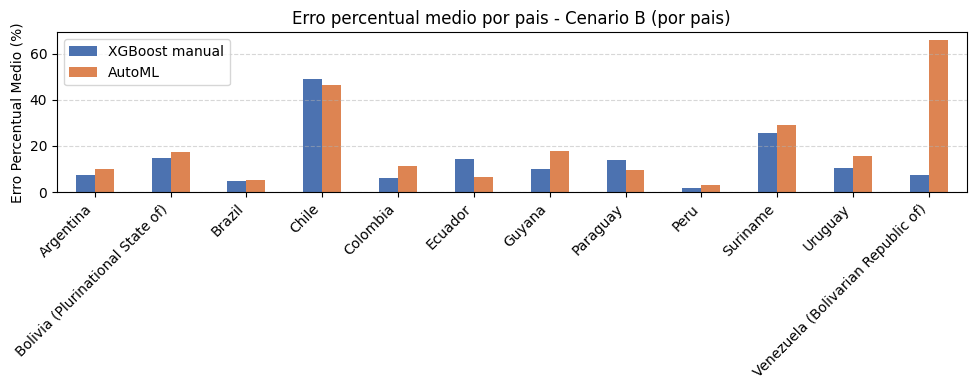

In [14]:
det = pd.DataFrame(DETALHES)

for cen in ['A', 'B']:
    sub = det[(det['Cenario'] == cen) & (det['Estrategia'] == 'por pais')]
    piv = sub.groupby(['Area', 'Metodo'])['Erro_pct'].mean().unstack()
    piv = piv[['manual', 'automl']]
    piv.columns = ['XGBoost manual', 'AutoML']

    ax = piv.plot(kind='bar', figsize=(10, 4),
                  color=['#4C72B0', '#DD8452'])
    ax.set_ylabel('Erro Percentual Medio (%)'); ax.set_xlabel('')
    ax.set_title(f'Erro percentual medio por pais - Cenario {cen} (por pais)')
    ax.grid(axis='y', ls='--', alpha=.5)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(f'fig_erro_pais_{cen}.png', dpi=150)
    plt.show()

### 7.3 Erro percentual medio por ano previsto

Formato analogo as Figuras 6, 8 e 11 do artigo. Evidencia a degradacao do
desempenho conforme a previsao se distancia do periodo de treino.

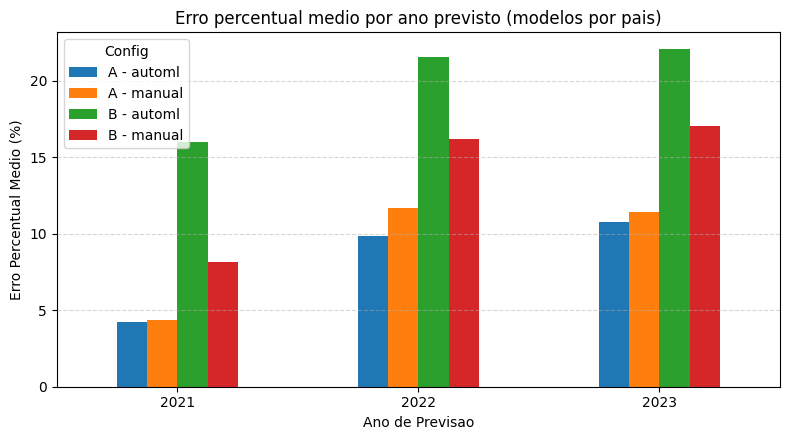

In [15]:
sub = det[det['Estrategia'] == 'por pais'].copy()
sub['Config'] = sub['Cenario'] + ' - ' + sub['Metodo']

piv = sub.groupby(['Ano', 'Config'])['Erro_pct'].mean().unstack()

ax = piv.plot(kind='bar', figsize=(8, 4.5))
ax.set_ylabel('Erro Percentual Medio (%)'); ax.set_xlabel('Ano de Previsao')
ax.set_title('Erro percentual medio por ano previsto (modelos por pais)')
ax.grid(axis='y', ls='--', alpha=.5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('fig_erro_ano.png', dpi=150)
plt.show()